**1. LOADING THE DATASET FIRST**

In [1]:
import numpy as np  # Does the heavy math: Handles numbers, calculations, and large lists of data (arrays) super fast.
import pandas as pd # Handles data tables: Works like Excel for Python to load, view, clean, and organize data.
import matplotlib.pyplot as plt # Draws basic charts: The core tool used to create standard graphs, line charts, and plots.
import seaborn as sns # Makes charts pretty: Built on matplotlib, it draws beautiful, complex statistical graphs with less code.

In [2]:
df = pd.read_csv('/content/drive/MyDrive/credit_risk_dataset.csv')
df.head() #shows the first 5 imformation of the table(data)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


2. **EDA (Exploratory Data Analysis)** - To check what kind of dataset it is

In [3]:
df.shape  # To check rows annd column
print(df.info()) # to check the data type in each column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


**3. MISSING VALUES** - Find the null values and the missing values in the dataset like which rows and column is null and empty to avoid error and to fix them

In [4]:
df.isnull().sum() #tells us which values is null in the form of true and false if used .isnull when addes .sum guve the real data


,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


**4. TARGET IMBALANCE** - Checks if the targets is balances or imbalanced ,
eg here in this dataset there are two targets one who paid and one who did not paid ,
these are 2 classes ,
the targets are in numbers 1 - the perosn who is gonna get the loan and 0 - who will not get the loan ,
class imbalance here in this dataset is 1 and 0,
class imbalance happens if one class value comes more often than the other class so the ml model will focus on the class whi appears more this is imbalance ,
there can be more than 2 targets

In [5]:
df.head()
df['loan_status'].unique() # shows the targets 1 mean gets the loand , 0 means did not get the loan
df['loan_status'].value_counts()  #check if there us classification imbalance or not guve hw many time each targets occurs
                          #and yes there is target imbalance as o comes more than 1 by a hige number


,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

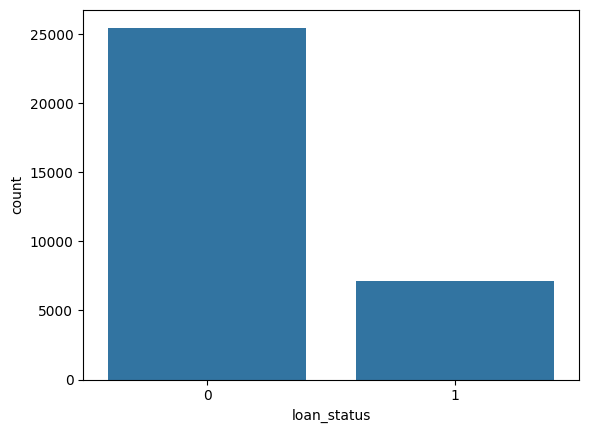

In [6]:
sns.countplot(x='loan_status',data=df) # to plot graph df is the dataset we have mentioned earlier
                  #compares 0 and 1 targets and class imbalance is happening and the ml will focus on the target 0

**5. OUTLIER (bad values)** - Check the outliers meaning values that are beyond meaning that are too much wrong and remove them to prevent errors

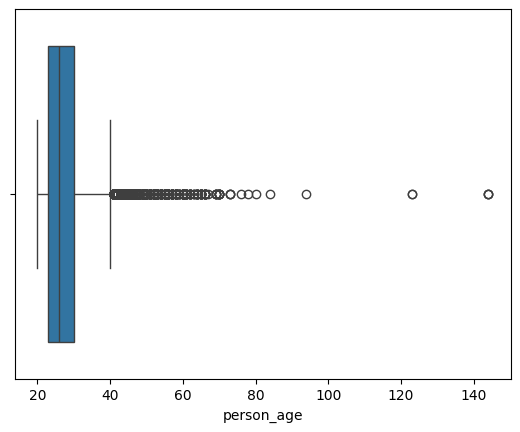

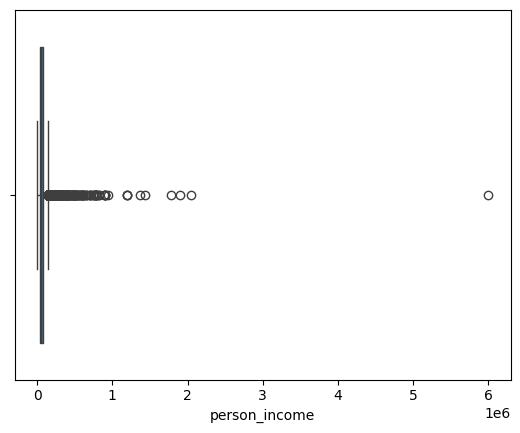

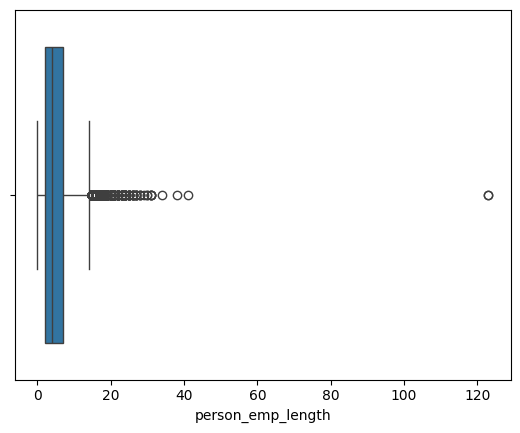

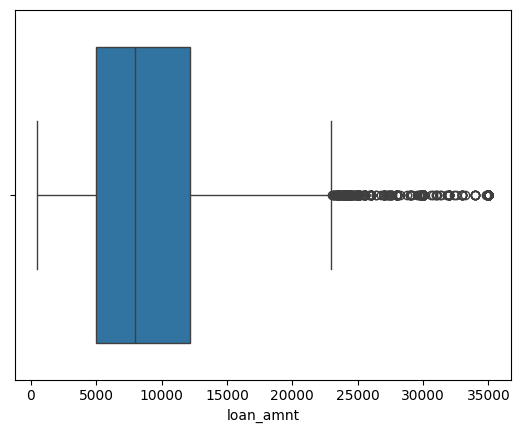

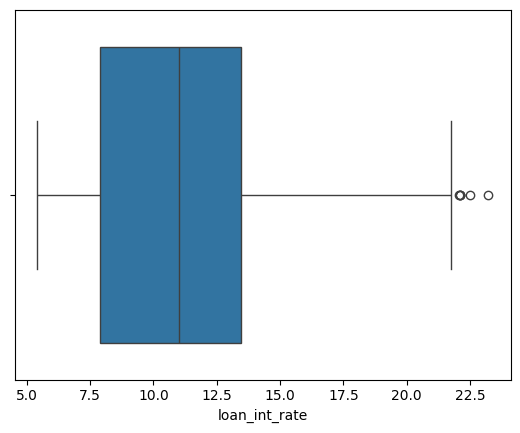

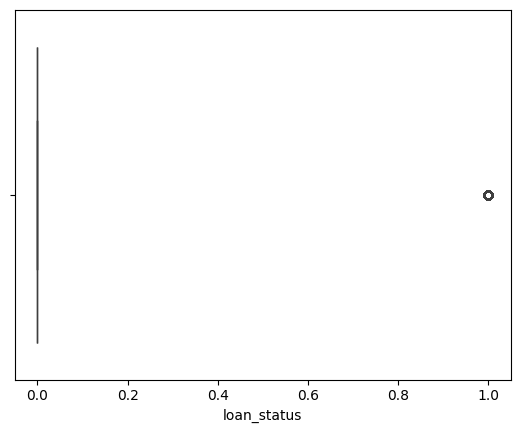

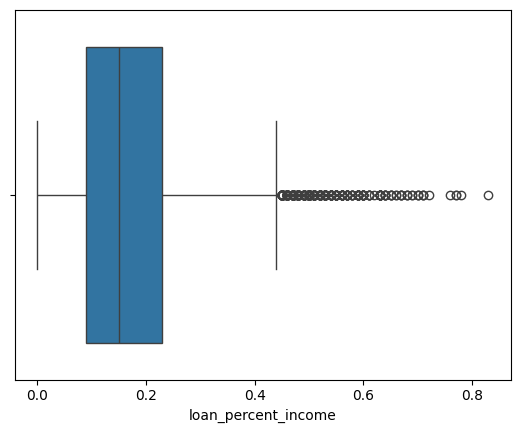

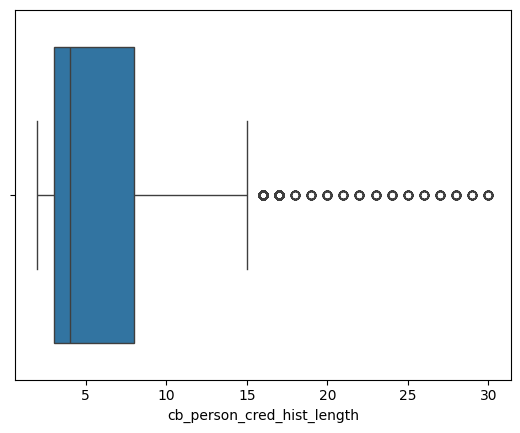

In [7]:
#we have to create a box plot to know how data are outliers abd box plot can only take data from numerical columns
numerical_cols= df.select_dtypes(include=np.number).columns #extarcts only the munerical values
numerical_cols
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [8]:
(df['person_age']>100).sum()

np.int64(5)

In [9]:
(df["person_emp_length"]>60).sum()

np.int64(2)

In [10]:
df.describe() # Provides a quick summary of numerical data (like average, min, max, etc.)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


**6. CORRELATION CHECK** - Helps us to check how many strong features are there, helps us to check repeated values

<Axes: >

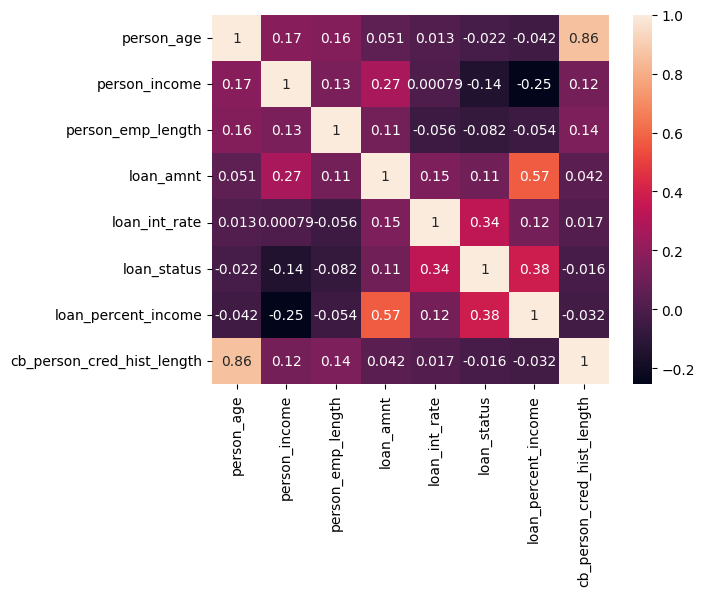

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True) # to check the correlation

**7. DATA VALIDATION AND HANDLING** To check if the data is good or bad, clean the data , remove ouliers basucally remove the bad values and make the dataset good for the ml model

In [12]:
df_copy=df.copy() # we make changes in a duplicate dataset not the original dataset
print(f"Original Rows: {df_copy.shape[0]}") # print the number of rows
df_copy.drop_duplicates(inplace=True) #to remove the duplicates
print(f"Rows after removing the duplicates: {df_copy.shape[0]}")

#remove ages below 18 and above 100 and remove employment lenght greater than extreme ouliers
df_copy = df_copy[(df_copy['person_age'] >= 18) & (df_copy['person_age'] <= 100)] # we do not want the answer in boolean terms thats why we cover it up with df_copy
df_copy = df_copy[df_copy['person_emp_length'] <= 60]
df_copy=df_copy[df_copy['loan_amnt']>0] # reomve the rows with negative imocme or loan amt
print("loan interest rate range from (min: 5.42 and max: 23.22 )")

Original Rows: 32581
Rows after removing the duplicates: 32416
loan interest rate range from (min: 5.42 and max: 23.22 )


In [13]:
df_copy.describe() # to check the interest rate but here interest rate is good enough here

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


**8.Features,Target and Train Test Split**



 We separate the data into input features and the target. - to know on which column we have to use standard scale and one hot encoding to prevent data leakage


 The target is whether the applicant defaulted or not.


 We split the data into a training part and a testing part.


 The model learns from the training part only.

**Standard Scaling:** Levels the playing field for numbers (forces a mean of 0, standard deviation of 1) so large values don't overpower small ones.

**One-Hot Encoding:** Converts text categories into binary columns (0s and 1s) so math-based models can read them.

The Data Leakage Rule: These techniques do not prevent leakage; doing them in the wrong order causes it.

To prevent leakage, memorize this exact sequence:

Split your data into train and test sets first.

Fit your scaler or encoder only on the training data to learn the patterns.

Transform both the training and test sets using those learned rules.

In [14]:
X=df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status'] # two categories 1 and o meaning true and false

In [15]:
from sklearn.model_selection import train_test_split # a library to train,test and split
X_train , X_test, y_train, y_test = train_test_split( X, y ,test_size=0.2 ,random_state=42,stratify =y) #to mantain the categories 1 and 0 to get equally divide them in train, test data we have to use this

In [16]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

**HANDLE CLASS IMBALANCE** - HERE ZERO IS COMING A LOT THEN THE ML MODEL WILL GOVE MORE ATTENTION TO 0 IT WLL BECOME BIAS WE HAVE TO FIX IT , WE WILL OUT SOME **CLASS WEIGHT** TO 1 TO PREVENT CLASS IMBALANCE
ALREASY INBUILT IN LOGISTIC REGRESSION
BASICALLY ASSIGN SOME WEIGHT IN 1 SO THAT MODEL DOESN'T BIAS

**WE ARE USING XG BOOST HERE** - SO IN HERE WE DINT HAVE CLASS TRAIN SO WE GOTTA ASS CLASS AND ASSIGN CLASS WEIGHT

In [17]:
y_train #0-> no loan
        # 1 -> yes loan
y_train.value_counts() # to seee the class weights, basiccaly class weight is the dominant weight/lighter weight

,count
loan_status,
0,19772
1,5445


In [18]:
neg , pos = np.bincount(y_train)
scale_weights = neg/pos

**this scale weights will be used by the xg_boost**

In [19]:
scale_weights

np.float64(3.6312213039485766)

without class weights xg_boost will
give wrong results

**we will create a first pipeline for logistic regression**

**Data Preprocessing — Pipelines & Column Transformer**



* Raw data is not ready for a model directly.


* We need to prepare numeric and text columns differently.


* We will build a Pipeline for each model.


* We will use ColumnTransformer to apply different steps to different columns.



Preprocessing for Logistic Regression

* Fill missing numeric values.


* Scale numeric values, since this model is sensitive to scale.


* Convert category columns into numbers using one-hot encoding

Logistic Regression: A classification algorithm used to predict binary outcomes, meaning it decides between two categories (e.g., Yes/No, Default/Did not Default).

Impute: The process of filling in missing or blank data points, usually by replacing empty spaces with the average, median, or most frequent value of that column.

Scale Numeric: Adjusting numerical data to a standard range so that large numbers (like a $50,000 salary) do not mathematically overpower smaller numbers (like 5 years of employment).

One-Hot-Encoding: Converting text-based categories (like "Rent" or "Own") into binary columns of 0s and 1s so mathematical models can understand them.

In [20]:
from sklearn.pipeline import Pipeline # we are creating 2 pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
preprosessor_lr= ColumnTransformer(   # tranfer columns in the respective functions(pipelines)
#pipeline for numerical column
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')), #this pipeline is only for numerical column and once the columns are fille standard scaler is applied
            ('scaler', StandardScaler())            #simple imputer -> standard scaler and data is processed on numerical
        ]), numeric_cols),
        #pipeline for categorical column
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant',fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

Without a pipeline: You manually write code to pass the data from step 1, to step 2, to step 3.

With a pipeline: You bundle all the steps into one single package. You run one command, and the data flows through all the cleaning and training steps automatically.

**now creating a pipeline for XG-BOOST**
Preprocessing for XGBoost

* Fill missing numeric values.


* No scaling needed here, since tree models don't need it.


* Convert category columns into numbers using one-hot encoding.

In [21]:
preprosessor_xg= ColumnTransformer(   # tranfer columns in the respective functions(pipelines)
#pipeline for numerical column
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
                                                                   #simple imputer -> no standard scaler and data is processed
        ]), numeric_cols),
        #pipeline for categorical column
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant',fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

for catgorical column it on hot encoding and for number columns its impute

**Stratified Cross-Validation**



* One single train-test split may not be reliable.


* We split the training data into five folds instead.


* Each fold keeps the same default vs repaid ratio.


* We check the model's score across all folds.

in fold

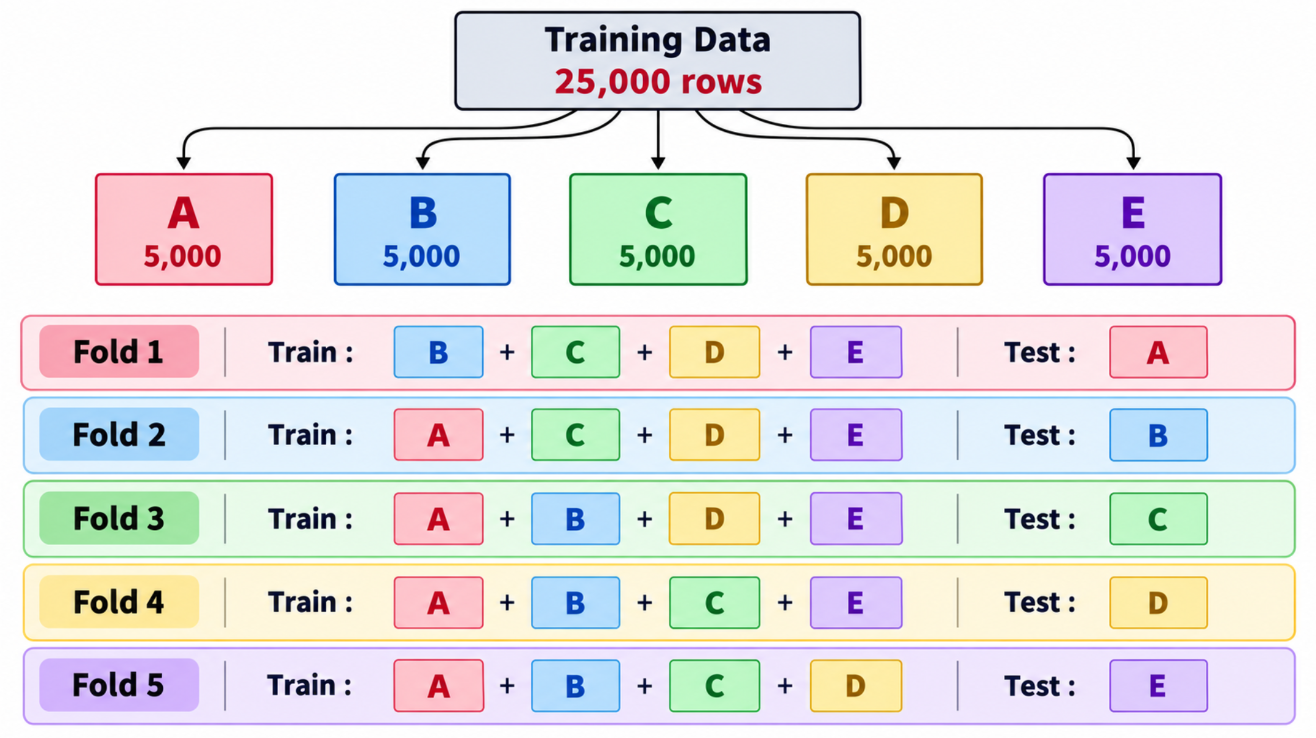




we train and test the data by slipting the main datat into as many nuber of folds as we want to chekc if the model is reiable or not

works only on small data
after the folds we will be evaluated the model and then we will find the **MEAN SCORE**

In [22]:
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits=5, shuffle = True, random_state=42)
scoring={'roc__auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
lr_cv_pipeline=Pipeline([
    ('preprocessor',preprosessor_lr),
 ('classifier',LogisticRegression(max_iter=1000,class_weight="balanced", random_state=42))
])                # we called the previous variable preprocessor_lr from the code where we created a pipeline

Logistic Regression, which is a statistical model commonly used for binary classification tasks in machine learning. It predicts the probability of a binary outcome (e.g., 0 or 1, Yes or No).



In [24]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
xgb_cv_pipeline=Pipeline([
    ('preprocessor',preprosessor_xg),        #scale_weights are used here if not used xgboost will give priority to 0 as it is the dominat datat than 1 so ye had to balance the data
 ('classifier',XGBClassifier( n_estimators=300,max_depth=5,
                             learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42))
])

  now time for iteration to check if the models are actually working

In [25]:
for cv_name, pipe in [("Logistic_Regression",lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:    #this is a for loop
                      cv_results=cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)#here cross validate a function after diciving the the datat inot 5 fold we will evaluate and then score the results in accuracy and all
                      print(cv_name)
                      print(f"ROC-AUC: {cv_results["test_roc__auc"].mean()}")
                      print(f'Accuracy:{cv_results["test_accuracy"].mean()}')
                      print(f'Precision:{cv_results["test_precision"].mean()}')
                      print(f'Recall:{cv_results["test_recall"].mean()}')
                      print(f'F1:{cv_results["test_f1"].mean()}')
                      print()

Logistic_Regression
ROC-AUC: 0.8705112830525306
Accuracy:0.8115949542892269
Precision:0.5448226008889892
Recall:0.7781450872359963
F1:0.6408013995933108

XGBoost
ROC-AUC: 0.9470945968526715
Accuracy:0.917952083139717
Precision:0.8190795992296656
Recall:0.7963269054178144
F1:0.8073360762846882



In [26]:
cv_results #exactly 5 folds now we have to calculate the mean scores
#ITS A DICTIONARY BTW

{'fit_time': array([1.26094842, 1.20020056, 1.58135653, 1.27161193, 0.83451748]),
 'score_time': array([0.17563033, 0.19874835, 0.16779685, 0.16457915, 0.09544301]),
 'test_roc__auc': array([0.95037143, 0.93802547, 0.94787183, 0.94916053, 0.95004373]),
 'test_accuracy': array([0.92089611, 0.91732752, 0.91631965, 0.91929407, 0.91592306]),
 'test_precision': array([0.82485876, 0.836     , 0.81314554, 0.82048872, 0.80090498]),
 'test_recall': array([0.80440771, 0.76767677, 0.79522498, 0.80165289, 0.81267218]),
 'test_f1': array([0.81450488, 0.80038296, 0.80408542, 0.81096145, 0.80674567])}

9. Baseline Model — Logistic Regression



* We start with a simple model first.


* This becomes our benchmark to beat.


* We train it and check its score on the test data.

In [27]:
baseline_model=Pipeline([
    ('Preprocessor',preprosessor_lr),
    ('Classifier',LogisticRegression(class_weight="balanced"))

])
baseline_model.fit(X_train,y_train) #traing the model ,the code for training

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('Classifier', LogisticRegression(class_weight='balanced'))])

7. Evaluation Helper Function



* We build one common function to check any model's performance.


* It will show accuracy, precision, recall, F1 score, and more.


* It will also show a confusion matrix and a precision-recall curve.

basically a common function for calling both the algoriths
we will wirte all the variabkes like accuracy and it will evaluate all

In [28]:
from sklearn.metrics import accuracy_score,classification_report,precision_score,recall_score,f1_score,confusion_matrix,precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns # Added this line
def evaluate_model(model_name,model,X_test,y_test, threshold=None):  #this is all for the baseline_model to check the accu, ralibility and all , and score basially to evaluate
  #y_pred = model.predict(X_test)
  y_pred_prob = model.predict_proba(X_test)[:,1] #we have create some matrices like accu,fi and all

  if threshold :
    y_pred = (y_pred_prob >= threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #metrices
  accuracy=accuracy_score(y_test,y_pred) #model overall performance
  precision_s=precision_score(y_test,y_pred) #meaning how many were right which i choose
  recall_s=recall_score(y_test,y_pred) # how much did i manage to find from the model from the total data
  f1=f1_score(y_test,y_pred) #the balance

  #plotting cofusion metrix
  cm=confusion_matrix(y_test,y_pred) #telle us how many time the mode can label the data correctly
  class_report = classification_report(y_test,y_pred)
  print(f"Best threshold:{best_threshold}")
  print(f"Accuracy:{accuracy:.2f}")
  print(f'Precision:{precision_s:.2f}')
  print(f'Recall:{recall_s:.2f}')
  print(f'F1:{f1:.2f}')
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)
  print(cm)

  #plotting comfusion metrix
  sns.heatmap(cm,annot=True,fmt="d")
  plt.xlabel("Predicted Values")
  plt.ylabel("Actual Values")
  plt.title(f"{model_name} Confusion Matrix")
  plt.show()

  #plotting ROC-AUC THROUGH AREA UNDER THE CURVE
  precisions,recalls,thresholds=precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

10. XGBoost Hyperparameter Tuning



* Now we move to a stronger model, XGBoost.


* A model has many settings called hyperparameters.


* We search for the best combination of these settings.


* We use cross-validation while searching, so the result is reliable.

In [29]:
xg_model= Pipeline([
    ('Preprocessor',preprosessor_xg),
    ('Classifier',XGBClassifier(learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42))
])
xg_model.fit(X_train,y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

now in the next code we evaluate the logistic model
so we will call a function we have created it known as evaluation helper function

now e caome back to our  Baseline Model — Logistic Regression

Best threshold:0.9996131062507629
Accuracy:0.82
Precision:0.56
Recall:0.79
F1:0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305

[[4094  849]
 [ 290 1072]]


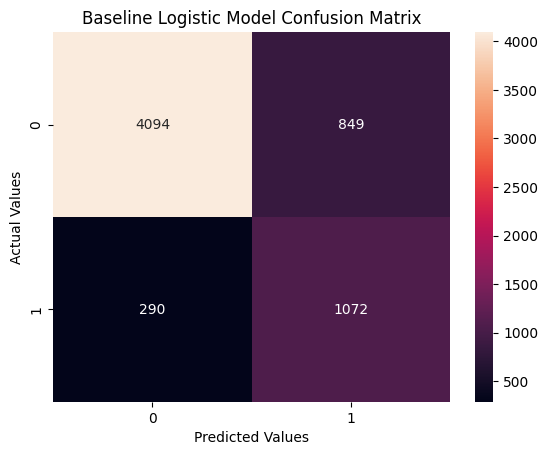

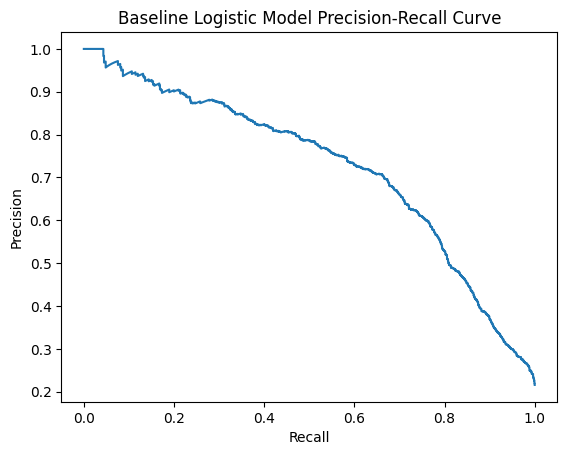

In [44]:
evaluate_model("Baseline Logistic Model",baseline_model,X_test,y_test)

Best threshold:0.9996131062507629
Accuracy:0.92
Precision:0.82
Recall:0.79
F1:0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305

[[4711  232]
 [ 281 1081]]


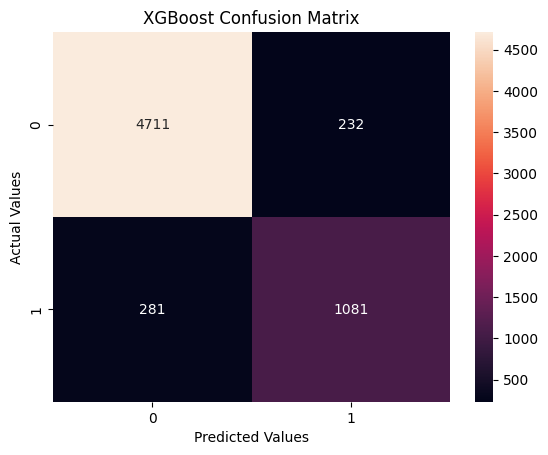

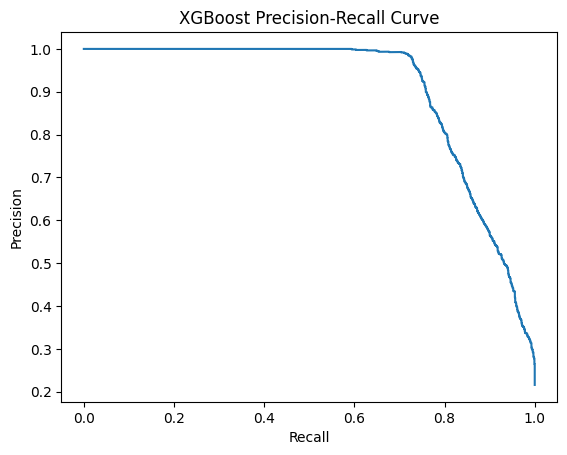

In [43]:
evaluate_model("XGBoost",xg_model,X_test,y_test)

now we will use hyperparameter tuning this is used to make chnages in the data
out hyperparameter tuning, it's a crucial step in machine learning where you try to find the best settings (hyperparameters) for your model to achieve optimal performance.

**we create a complete parameter grid for xgb boost model under these are all parameters of xgboost**

In [32]:
from scipy.stats import uniform, randint

In [33]:
from sklearn.model_selection import RandomizedSearchCV
import scipy.stats as stats

param_grid={
    "Classifier__n_estimators":randint(150,600),
    "Classifier__max_depth":randint(3,9),
    "Classifier__learning_rate":uniform(0.01,0.5),
    "Classifier__subsample": uniform(0.6,0.4), #randomly selects row to train the model make it harder for the modle
     "Classifier__colsample_bytree": uniform(0.6,0.4),
    "Classifier__min_child_weight": randint(1,10),
    "Classifier__gamma": uniform(0,5)
}

In [34]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('Preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'Classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a54e6a62ad0>,
                                        'Classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a54e6a54590>,
                                        'Classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a54e6a62710>},
                   scoring='average_precision', verbose=1)

In [35]:
random_search.best_score_ #this is to search the best score

np.float64(0.9043211194262802)

In [37]:
random_search.best_params_ #this is to search the best parameters

{'Classifier__colsample_bytree': np.float64(0.8591604578286935),
 'Classifier__gamma': np.float64(0.8151619501127644),
 'Classifier__learning_rate': np.float64(0.12687886177521518),
 'Classifier__max_depth': 6,
 'Classifier__min_child_weight': 7,
 'Classifier__n_estimators': 565,
 'Classifier__subsample': np.float64(0.9694660738101265)}

compare both the models


Best threshold:0.9996131062507629
Accuracy:0.82
Precision:0.56
Recall:0.79
F1:0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305

[[4094  849]
 [ 290 1072]]


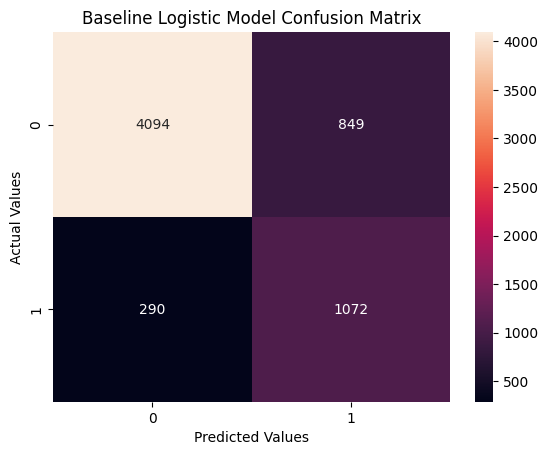

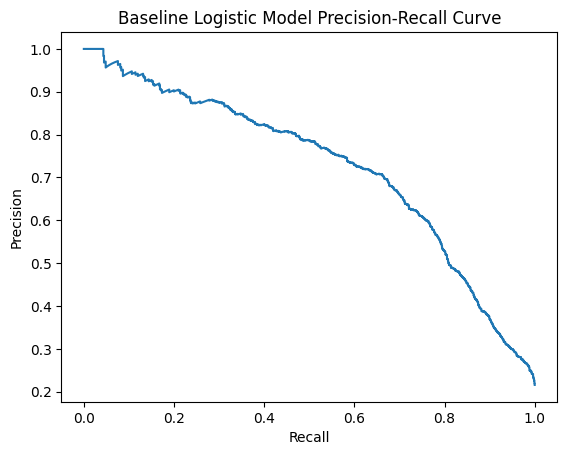

In [42]:
evaluate_model("Baseline Logistic Model",baseline_model,X_test,y_test)

Best threshold:0.9996131062507629
Accuracy:0.92
Precision:0.82
Recall:0.79
F1:0.81

XGB_model Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305

[[4711  232]
 [ 281 1081]]


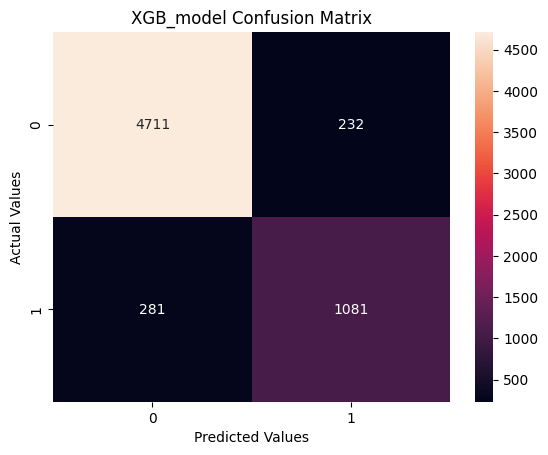

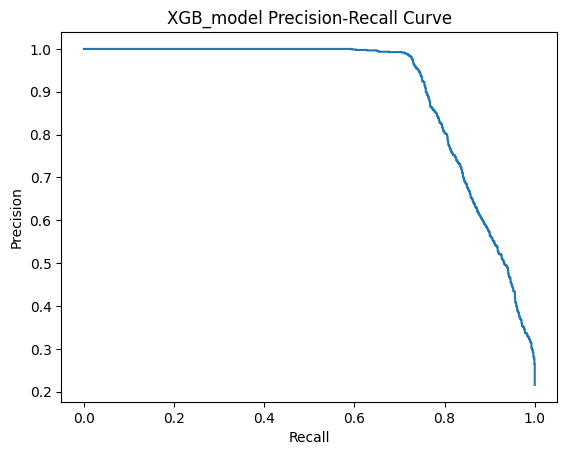

In [41]:
#passing the model after hyperparameter tuning
evaluate_model("XGB_model",xg_model,X_test,y_test)

12. Optimizing the Classification Threshold



* The model gives a probability, not a direct yes or no.


* We decide a cut-off point to turn it into a decision.


* We check different cut-off points and pick the best one.

Best threshold:0.9996131062507629
Accuracy:0.78
Precision:1.00
Recall:0.00
F1:0.00

XGB_model Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       1.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.89      0.50      0.44      6305
weighted avg       0.83      0.78      0.69      6305

[[4943    0]
 [1361    1]]


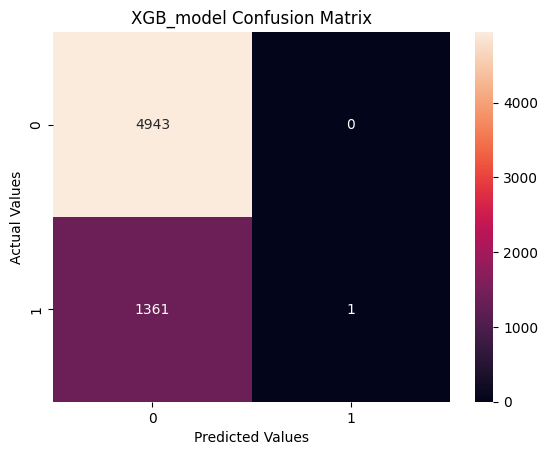

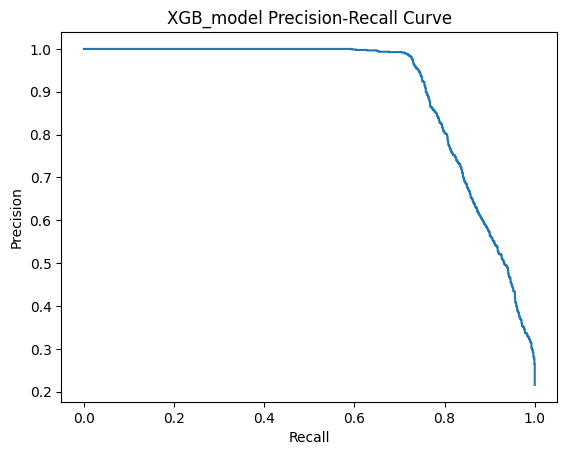

In [40]:
#before calculating the threshold we have to calculate some things
#Get the prob. of class 1 from XGBoost
prob= xg_model.predict_proba(X_test)[:,1]

#For each threshold calculate Precision and Recall
precisions ,recalls,thresholds=precision_recall_curve(y_test,prob)
#thresholds

#Calculate F1 score for each threshold
f1=2* (precisions -recalls )/(precisions + recalls + 1e-9)
f1

# get the threshold that produces the highest score
best=np.argmax(f1[:-1])
best_threshold = thresholds[best] #TO CHECK WHERE EXACTLY WE ARE GETTING THIS BEST VALUE , BASICALLY ON WHCH THRESHOLD
evaluate_model("XGB_model",xg_model,X_test,y_test,best_threshold)


**probability calibration**
13. Probability Calibration



* Sometimes a model's probability doesn't mean what it says.


* For example, 30% risk should truly mean a 30% chance.


* We check this with a calibration plot.


* We fix it if the probabilities are off.



**Simple Example to Remember**
Think of a weather app predicting rain. If the app predicts an **80% chance of rain** across 10 different days, it should actually rain on exactly 8 of those days. If it only rains on 4 of those days, the app's probability is uncalibrated (it was overconfident). Calibration mathematically adjusts the model so that its stated confidence exactly matches the real-world outcome frequency.

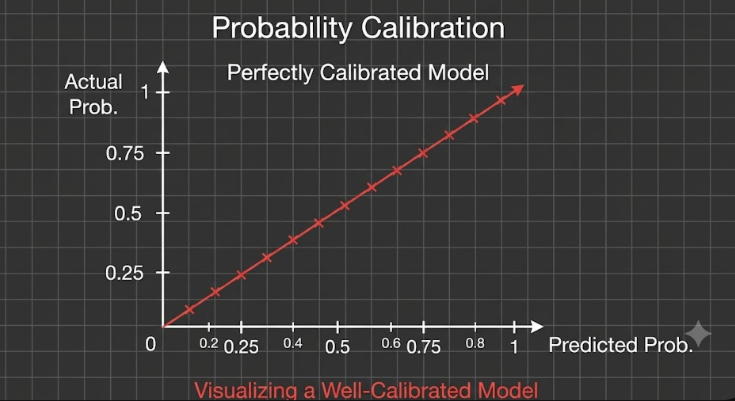

**Methods by which we can fix the poorly calibrated model.**

1. **Platt Scaling/ Sigmoid** -> Adjust the probabilites using a sigmoid curve.


2. **Isotonic Regression** -> Learn a flexible mapping from old prob. - better prob. (non-linear calib...


3. **Temperature Scaling** -> Adjust the confidence of neural-network predictions using one temperatu...



---

**Simple Example for Your Notes**

Think back to the Explainable AI mini-project you did for breast cancer detection using Random Forests. Random Forest models naturally struggle with probability calibration, often clustering their raw probabilities away from true 0 or 1.

If your model outputs a 70% probability that a sample is malignant, but historically only 50% of samples given that exact score actually are, the model is uncalibrated. Here is how these fixes apply in practice:

* **Platt Scaling (Sigmoid):** This method takes your model's 70% output and pushes it through a smooth S-curve equation to drag the reported probability down to the true 50%. It works well even if your dataset isn't massive.
* **Isotonic Regression:** Instead of a smooth curve, this creates a custom, non-linear step-function to map the old, inaccurate probabilities to the new, accurate ones. It is much more flexible but requires a large dataset to avoid overfitting.
* **Temperature Scaling:** If you were using a deep neural network instead (like in your sign language recognition prototype), this method acts like a master volume dial. It scales down the network's overconfidence across the board using a single number (the "temperature"), softening the probabilities without changing which class the model ultimately predicts.

In [74]:
#make a calibrated model the XGB MODEL - BASICALLY FIX THE HE MODEL IS IT IS POORLY CALIBERATED
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model=random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(best_model, # this is model where we have use huperparameter tuning
                                          method='sigmoid', cv=5)
calibrated_model.fit(X_test, y_test)


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('Preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.12687886177521518),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=7,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=565,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

**`calibrated_model` (The Parent Translator)**
Imagine a little kid who always shouts "I am 100% sure!" about everything, even when they are just guessing. This model is like a parent who translates for them, saying, "When he says 100%, he actually means about 60%." It turns exaggerated, overconfident guesses into realistic ones.

**`.fit(...)` (The Watching Phase)**
This is the parent watching the kid play a guessing game. The parent sits back and pays close attention to see exactly how often the kid is actually right when they yell "I'm 100% sure!" so they can figure out the perfect translation rule.

**`(X_test, y_test)` (The Flashcards)**
These are the flashcards used during the guessing game. `X_test` are the front of the cards (the pictures shown to the kid), and `y_test` is the actual correct answer printed on the back so the parent can check if the kid was right or wrong.


In [75]:
#get probabilities
uncalibrated=xg_model.predict_proba(X_test)[:,1]

calibrated=calibrated_model.predict_proba(X_test)[:,1]


In [76]:
uncalibrated

array([0.8254656 , 0.25111562, 0.9782833 , ..., 0.48520026, 0.07587515,
       0.05467961], dtype=float32)

In [77]:
calibrated

array([0.88669073, 0.25984366, 0.91152135, ..., 0.42028362, 0.05441121,
       0.02590682])

In [78]:
#create a caliberated curves to commpare
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [79]:
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

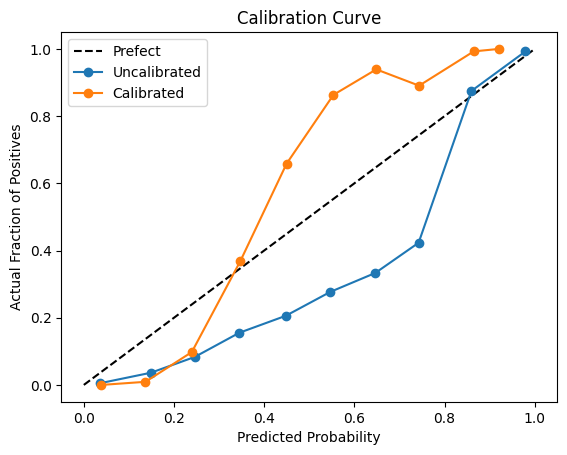

In [80]:
#plot the garphs of both the curves of caliberated and uncaliberated
plt.plot([0,1],[0,1],'k--', label="Prefect")
plt.plot(predicted_uncal,
         actual_uncal,
         "o-",
         label="Uncalibrated")
plt.plot(predicted_cal,
         actual_cal,
         "o-",
         label="Calibrated")
plt.xlabel("Predicted Probability")
plt.ylabel("Actual Fraction of Positives")
plt.title("Calibration Curve")
plt.legend()
plt.show()

above there are 2 model one i caliberated and one uncaliberated we choose the mode whch is closer to the black line that is close to perfect model , the balck line reresenst the higly caliberated model

# . SHAP Interpretation — Global & Local



* SHAP helps us understand why the model makes a decision.


* It is a way of explaining a "black box" model.



---

**Simple Example for Your Notes**
Think of the Explainable AI project you built for breast cancer detection. A "black box" model like a Random Forest might output a prediction (e.g., "Malignant") without telling you *how* it reached that conclusion. SHAP cracks open that box.

* **Global Interpretation:** Looking at the big picture across all patients (e.g., "Overall, cell size is the most important feature for the model").
* **Local Interpretation:** Looking at one specific patient (e.g., "For *this exact patient*, the prediction was 'Malignant' specifically because their cell uniformity score was unusually high").

shap can tell you how much each particular thing contributes to make predictions

The Scenario: Imagine a student has an 85% predicted probability of getting placed in a job.
The SHAP Role: SHAP acts like a detective that asks, "Why did the model predict 85%?"
The Breakdown: It analyzes every single input (like grades, internship experience, communication skills) and calculates exactly how much each specific factor contributed to pushing that probability up or down.

SHAP tells which features pushed the predictions up or down and how much?v

Local explanation   This shows why one specific applicant got their score.

It breaks the score down feature by feature.
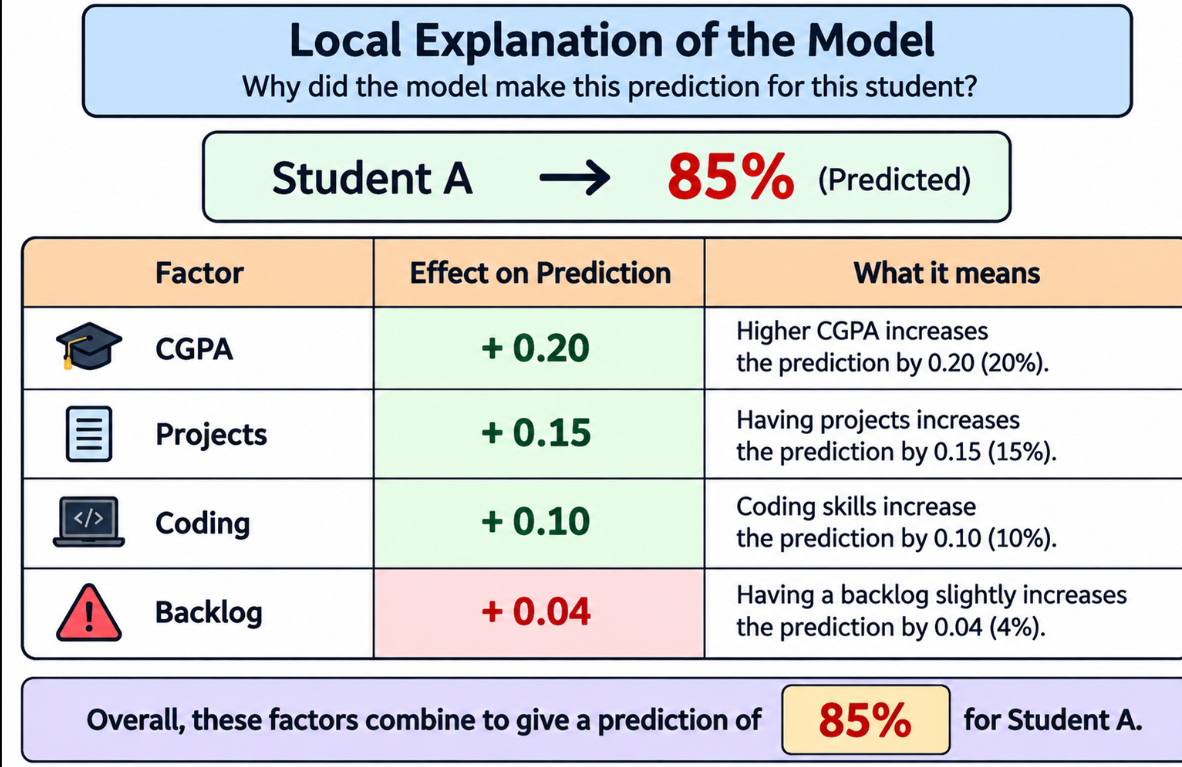

WHEN WE ARE TALKING ABUT HE COMPLETE MODEL ITS GOBAL EXPPLNATION AND FOR LOCAL IT JUST ONE VARIABLE

**GLOBAL EXPLANATION**
It shows you which features are the most important overall across the entire dataset and whether specific features generally increase or decrease the risk prediction. It provides a "big picture" view of how the model makes decisions.

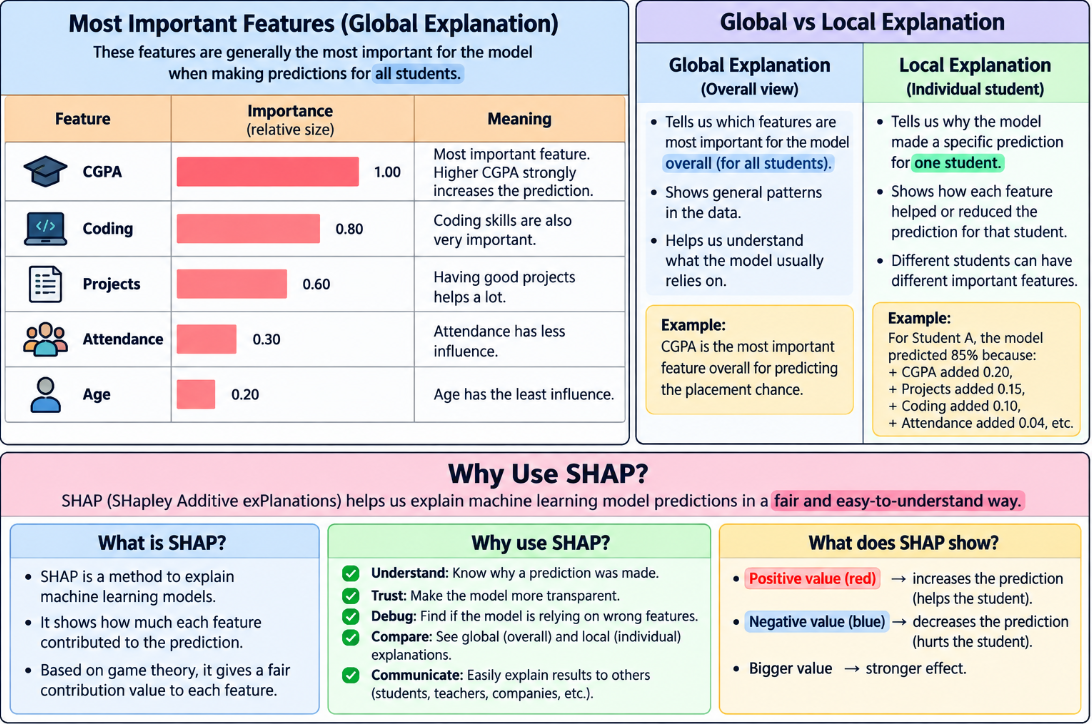

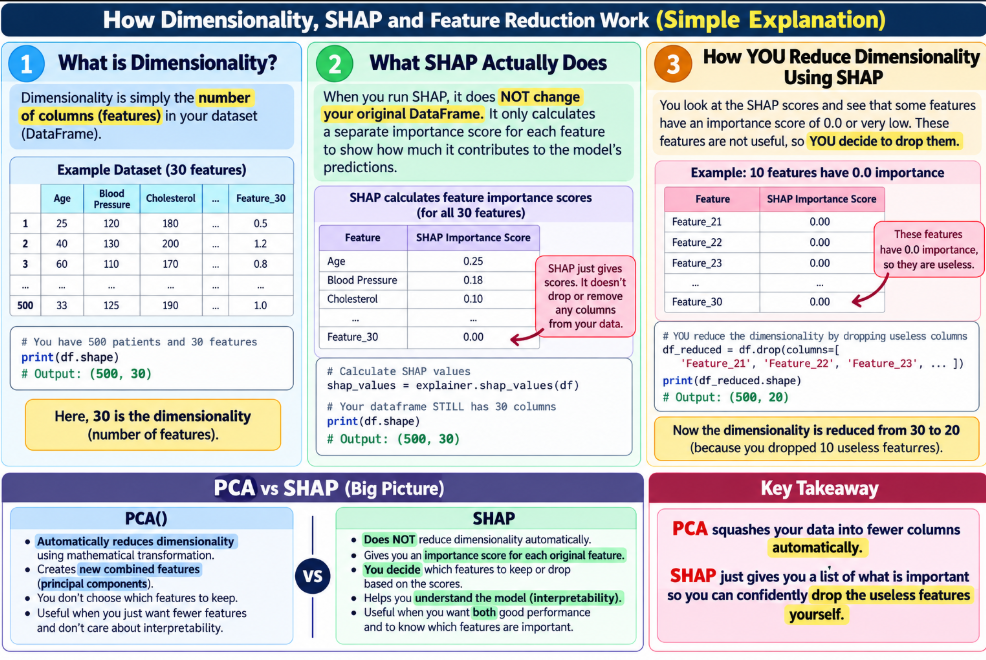

In [81]:
!pip install shap
import shap

In [82]:
#some things to do to perform shap

##2. Get the Trained XGBoost classifier model out of the pipeline - the pipeline we created we have to import the tarined classifier model
xgb_classifier = xg_model.named_steps['Classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [83]:
#3. Transform X_test using the same preprocessing used for training - we can train the model to know that frm the actual feature which feature contributes the most
X_test_transformed = xg_model.named_steps['Preprocessor'].transform(X_test)
X_test_transformed

array([[2.4000e+01, 3.0000e+04, 1.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [2.3000e+01, 6.0000e+04, 6.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [2.9000e+01, 1.8000e+04, 2.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       ...,
       [2.5000e+01, 4.8996e+04, 8.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [2.7000e+01, 1.1500e+05, 1.1000e+01, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [3.2000e+01, 5.0000e+04, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00]])

In [84]:
#4. Get feature names after one-hot enocding , so plots are readable
feature_names = xg_model.named_steps['Preprocessor'].get_feature_names_out()

In [85]:
#convert to a data frame for cleaner SHAP plots
X_test_df=pd.DataFrame(X_test_transformed, columns=feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [86]:
#create shap explananer for tree basd model basucally to now which model affects or contributes the most
explainer = shap.TreeExplainer(xgb_classifier) #a model is created

In [87]:
#calculate every SHAP value for evry row that are in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]], dtype=float32)

In [88]:
shap_values[5] #basically in the output those are all the features that contributes for the predictionn of the 5 row/applicant

array([ 2.5693566e-02, -8.3614630e-01, -1.7286925e-02, -8.7159630e-03,
       -5.8070445e-01, -4.1112086e-01,  5.0949983e-02,  6.0737142e-03,
       -6.1365054e-04,  8.3771028e-02, -3.0887976e-01, -4.9950812e-02,
       -3.1072120e-03, -4.4103891e-02, -8.1458546e-02, -2.0882446e-02,
        1.7620784e-01,  1.1165806e-01, -1.7614496e-01,  5.6751363e-02,
       -7.8791454e-02, -2.2548350e-02, -1.2131979e-02, -9.6205277e-03,
       -1.0001900e-02,  0.0000000e+00], dtype=float32)

what we did is

1.  first we imported
2. the crete a base model, the training the model
3. the training the model to make predictions
4. we extracted all the features (meaning all the columns that are helping in the predictions)    
5.   create a dataframe to explan better
6. create a explainer us tell us which fetaure contributes hiw much , like percentage which model and all



Global explanation

* This shows which features matter most overall.


* It also shows if a feature increases or decreases risk.

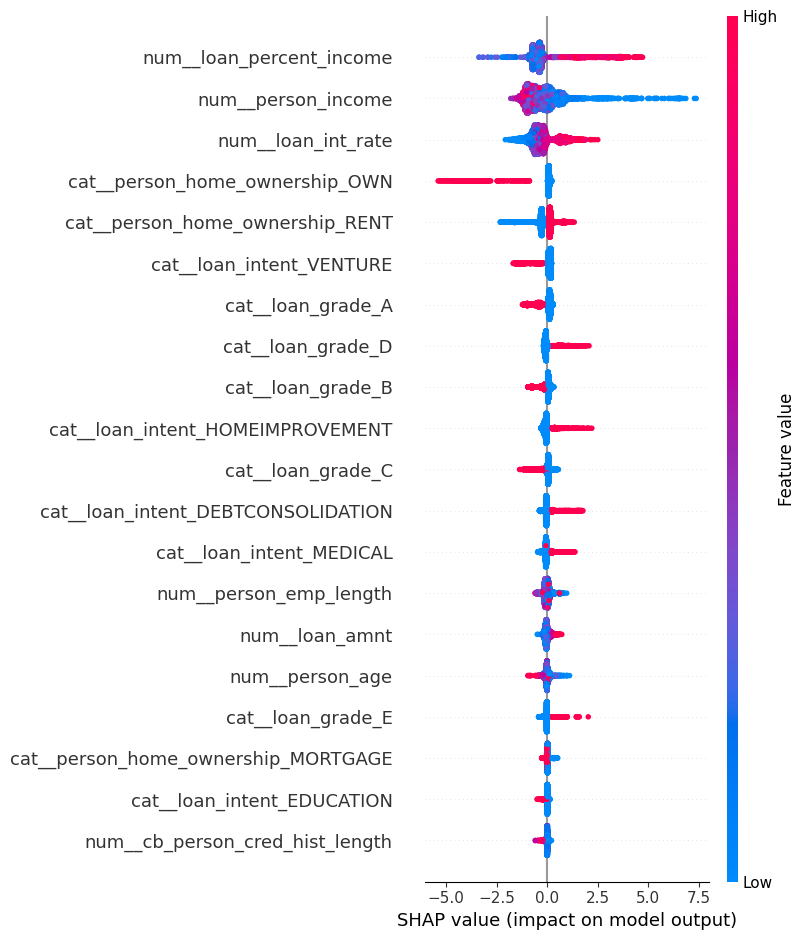

In [89]:
shap.summary_plot(shap_values,X_test_df) #red mean high contribution
                                         #blue means low contribution
                                         #this is how we check golbal explnation
                                         #CORRELATION HEATMAP

Local explanation

* This shows why one specific applicant got their score.


* It breaks the score down feature by feature.

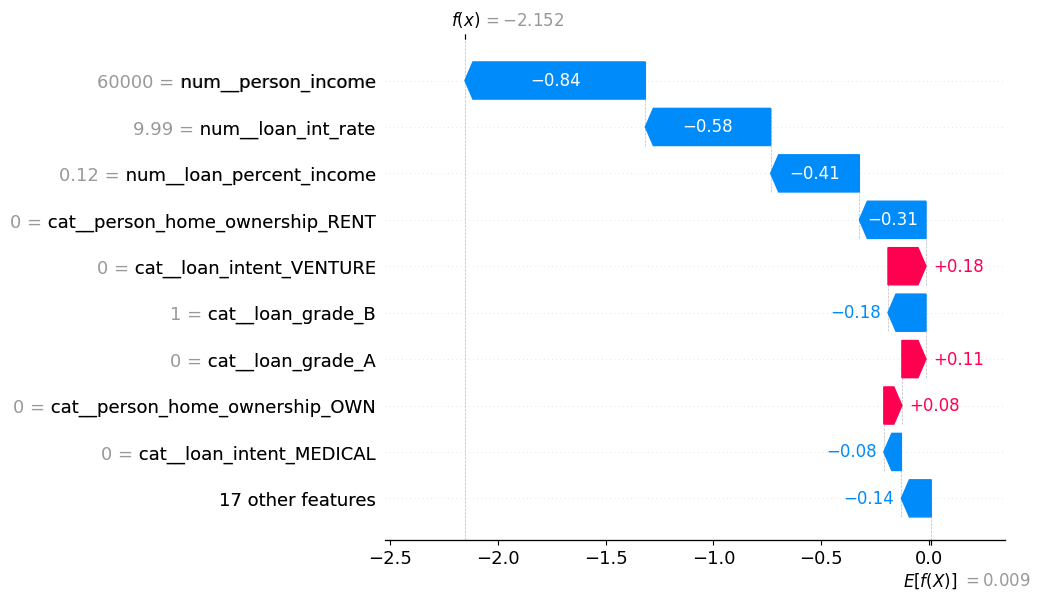

In [90]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index], #values of that row
        base_values=explainer.expected_value, # guve the values predicted by the model
        data=X_test_df.iloc[row_index], #gives the actual values #iloc= index location
        feature_names=feature_names
    )
)


# THIS GRAPH IS OF LOCAL EXPLANATION GRAPH
# THIS GIVES WHICH COLUMNS COONTRIBUTES HOW MUCH BASCIALLY HOW MUCH ON COLUMN CONTRIBUTES
#THIS IS HOW SHAP HELPS US

***15. Analyzing False Positives & False Negatives***



* The model will not be perfect.


* False positives are safe people wrongly marked risky.


* False negatives are risky people wrongly marked safe.


* We study these cases to understand where the model struggles.

In [91]:
#Get predictions from the best performing XGBoost model on the test set
y_pred = random_search.best_estimator_.predict(X_test)

# Create a DataFrame to inspect our predictions against actual values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [92]:
result_df #the last 2 new columns are actual and predicted

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [93]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']==0) & (result_df['predicted']==1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [94]:
print(f'False positive: {len(false_positive)}')
print(f'False negative: {len(false_negative)}')

False positive: 215
False negative: 266


**DONE THE MODEL IS TRAINED NOW TO CREATE A API AND EXPORT**

**Logistic Regression : This was implemented as the baseline model. It serves as a simple, interpretable starting point to establish a performance benchmark for the classification task.**

**XGBoost: This is a more advanced gradient-boosting algorithm. After evaluating both, the instructor chose to focus on and refine the XGBoost model for the final production-ready system.**

**Why choose XGBoost?
XGBoost is generally chosen in production environments for credit risk because it typically offers superior predictive performance, handles complex non-linear relationships between features more effectively than linear models, and provides robust tools for handling tabular data with class imbalances . The instructor further refined this model through hyperparameter tuning and probability calibration to ensure it was reliable and "production-ready" for the final deployment**

Picking the Winner: two models, but We picked the XGBoost one because We made it the smartest through hyperparameter tuning. Think of this like adjusting the knobs on a machine until it runs perfectly.
Saving the Brain: We used a tool to save his model into a small file. This is like saving a game so you can open it on another computer later .
Setting the Rule: saved a "threshold" . This is just a rule like, "If the score is above 0.5, say the loan is risky." It tells the app exactly when to say "Yes" or "No" to a loan.

In [95]:
#export the model
import joblib
joblib.dump(calibrated_model,"credit_risk_model.pkl") #used to export the model as a file

['credit_risk_model.pkl']

In [97]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# 1. Get probabilities from the CALIBRATED model, not the old xg_model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

# 2. Re-run the same threshold search, now on the correct probability scale
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold:", best_threshold)

New threshold: 0.393500813201913


In [99]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']